In [1]:
# Run from the repository root, notebooks/, or another repository subdirectory.
from pathlib import Path
import sys
import json
from tempfile import mkdtemp
from time import perf_counter

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/evaluation.py").is_file()
             and (p / "data/bank_marketing_qos_encoded.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start this notebook with a working directory inside qos-rbc-experiments.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline

from src.preprocessing import make_preprocessor
from src.sketches import balanced_feature_bucket, sparse_jl_features
from src.machine_size import max_row_sparsity, matrix_nnz, qos_svm_machine_size
from src.evaluation import (
    make_ridge_classifier, make_stratified_cv, cross_validation_scores,
    run_sketch_sweep, summarize_sweep,
)

Matplotlib is building the font cache; this may take a moment.


In [2]:
DATA_PATH = ROOT / "data/bank_marketing_qos_encoded.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df.columns.tolist())

(45211, 23)
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y', 'age_bin', 'age_code', 'job_code', 'housing_code', 'loan_code', 'qos_address']


In [3]:
target = "y"

derived_columns = [
    "age_bin",
    "age_code",
    "job_code",
    "housing_code",
    "loan_code",
    "qos_address"
]

feature_columns = [
    col for col in df.columns
    if col != target and col not in derived_columns
]

X_raw = df[feature_columns].copy()

y = (
    df[target]
    .map({"no": 0, "yes": 1})
    .to_numpy()
)

print("Original features:")
print(feature_columns)

print("\nX_raw shape:", X_raw.shape)
print("Positive fraction:", y.mean())

Original features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']

X_raw shape: (45211, 16)
Positive fraction: 0.11698480458295547


In [4]:
# Explicit Bank configuration: ordering is part of the validated encoding.
categorical_columns = [
    "job", "marital", "education", "default", "housing", "loan",
    "contact", "month", "poutcome",
]
numeric_columns = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
assert set(feature_columns) == set(categorical_columns + numeric_columns)

ALPHA = 10.0
SOLVER = "auto"
N_SPLITS = 5
CV_SEED = 42
bucket_sizes = [4, 8, 12, 16, 24, 32, 40, 51]
seeds = [42, 123, 456, 789, 2026]
# run_sketch_sweep uses the validated factory defaults; fail on config drift.
assert make_ridge_classifier().alpha == ALPHA
assert make_ridge_classifier().solver == SOLVER
print("Categorical:", categorical_columns)
print("Numeric:", numeric_columns)

Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Numeric: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


In [5]:
preprocessor = make_preprocessor(categorical_columns, numeric_columns)
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", make_ridge_classifier(alpha=ALPHA, solver=SOLVER, class_weight="balanced")),
])

In [6]:
cv = make_stratified_cv(n_splits=N_SPLITS, seed=CV_SEED)

balanced_scores = cross_validation_scores(
    model,
    X_raw,
    y,
    cv=cv,
    scoring="balanced_accuracy"
)

accuracy_scores = cross_validation_scores(
    model,
    X_raw,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Balanced accuracy scores:", balanced_scores)
print("Mean balanced accuracy:", balanced_scores.mean())
print("Std balanced accuracy:", balanced_scores.std())

print("\nAccuracy scores:", accuracy_scores)
print("Mean accuracy:", accuracy_scores.mean())

Balanced accuracy scores: [0.82231648 0.82594736 0.82232553 0.83685578 0.82065146]
Mean balanced accuracy: 0.8256193229214974
Std balanced accuracy: 0.005878825758107588

Accuracy scores: [0.85635298 0.86076089 0.85202389 0.86175625 0.85268746]
Mean accuracy: 0.8567162938955939


In [7]:
X_encoded = preprocessor.fit_transform(X_raw)

print("Encoded shape:", X_encoded.shape)
print("Type:", type(X_encoded))

Encoded shape: (45211, 51)
Type: <class 'numpy.ndarray'>


In [8]:
N, D = X_encoded.shape
s = max_row_sparsity(X_encoded)
nnz = matrix_nnz(X_encoded)
print("N:", N)
print("D:", D)
print("Maximum row sparsity s:", s)
print("Nonzero count:", nnz)
print("Mean row sparsity:", nnz / N)

N: 45211
D: 51
Maximum row sparsity s: 16
Nonzero count: 723376
Mean row sparsity: 16.0


In [9]:
qos_machine_size = qos_svm_machine_size(N, D, s)
print("Estimated QOS machine size (row-only convention):", qos_machine_size)

Estimated QOS machine size (row-only convention): 41


In [10]:
paper_classifier = make_ridge_classifier(
    alpha=ALPHA,
    solver=SOLVER
)

balanced_classifier = make_ridge_classifier(
    alpha=ALPHA,
    solver=SOLVER,
    class_weight="balanced"
)

paper_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", paper_classifier)
])

balanced_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", balanced_classifier)
])

In [11]:
paper_accuracy = cross_validation_scores(
    paper_model,
    X_raw,
    y,
    cv=cv,
    scoring="accuracy"
)

paper_balanced_accuracy = cross_validation_scores(
    paper_model,
    X_raw,
    y,
    cv=cv,
    scoring="balanced_accuracy"
)

balanced_accuracy = cross_validation_scores(
    balanced_model,
    X_raw,
    y,
    cv=cv,
    scoring="balanced_accuracy"
)

print("Paper-style Ridge:")
print("  Mean accuracy:", paper_accuracy.mean())
print("  Mean balanced accuracy:", paper_balanced_accuracy.mean())

print("\nBalanced Ridge:")
print("  Mean balanced accuracy:", balanced_accuracy.mean())

Paper-style Ridge:
  Mean accuracy: 0.8995155858234207
  Mean balanced accuracy: 0.6300640934600773

Balanced Ridge:
  Mean balanced accuracy: 0.8256193229214974


In [12]:
X_full = np.asarray(X_encoded, dtype=float)

print(X_full.shape)

(45211, 51)


### What this experiment measures

Ridge classification scores are empirical classical cross-validation results.
Feature bucketing and signed sparse JL are classical simulations of feature
compression. QOS machine size is theoretical resource accounting, **not measured
quantum hardware usage or an executed quantum classifier**. The formula's `+4`
means three logical qubits plus one classical scalar register in the reference's
accounting units. Streaming dimension and sparse nonzero count are calculated
storage proxies, not measured runtime or byte-for-byte memory comparisons.

**Preserved limitations:** baseline pipelines fit preprocessing inside each CV
fold, while the sweeps below use `X_full`, fitted on the entire dataset before
CV. This known preprocessing leakage is preserved for reproducibility, not
corrected by this refactor. Resource estimates use maximum **row** sparsity;
the QOS reference uses maximum row-or-column sparsity. The value 41 is conditional
on our row-only convention.

Dense balanced bucketing deliberately stays dense to preserve Ridge's automatic
solver path. The imported sketch retains the original division/accumulation
order, balanced assignments, normalization, and seeds.

In [13]:
X_16 = balanced_feature_bucket(
    X_full,
    n_buckets=16,
    seed=42
)

print(X_16.shape)

(45211, 16)


In [14]:
scores_16 = cross_validation_scores(
    make_ridge_classifier(
        alpha=ALPHA,
        solver=SOLVER
    ),
    X_16,
    y,
    cv=cv,
    scoring="accuracy"
)

print("16-feature mean accuracy:", scores_16.mean())

16-feature mean accuracy: 0.8875052328691915


In [15]:
balanced_scores_16 = cross_validation_scores(
    make_ridge_classifier(
        alpha=ALPHA,
        solver=SOLVER,
        class_weight="balanced"
    ),
    X_16,
    y,
    cv=cv,
    scoring="balanced_accuracy"
)

print(
    "16-feature balanced accuracy:",
    balanced_scores_16.mean()
)

16-feature balanced accuracy: 0.7816400107805279


In [16]:
# Never export into the immutable original results directory.
validation_root = ROOT / "validation/bank_marketing"
validation_root.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = Path(mkdtemp(prefix="run-", dir=validation_root))
print("Separate validation output directory:", OUTPUT_DIR)
sweep_seconds = {}

Separate validation output directory: /Users/Surface/code/qos-rbc-experiments/validation/bank_marketing/run-29qfoy4_


In [17]:
started = perf_counter()
results_df = run_sketch_sweep(
    X_full, y, balanced_feature_bucket,
    dimensions=bucket_sizes, seeds=seeds, cv=cv,
    sparsity_fn=max_row_sparsity, nnz_fn=matrix_nnz,
    qos_size_fn=qos_svm_machine_size,
)
sweep_seconds["bucket"] = perf_counter() - started
print("Bucketing runs:", len(results_df), "seconds:", sweep_seconds["bucket"])

Bucketing runs: 40 seconds: 6.170235958066769


In [18]:
results_df.head()

,k,seed,paper_accuracy,balanced_accuracy,streaming_size,sparse_size,qos_size,max_sparsity
0,4,42,0.880958,0.701793,4,180844,39,4
1,4,123,0.881754,0.682704,4,180844,39,4
2,4,456,0.883369,0.662884,4,180844,39,4
3,4,789,0.881445,0.730323,4,180844,39,4
4,4,2026,0.882374,0.676478,4,180844,39,4


In [19]:
summary = summarize_sweep(results_df)
summary

,k,paper_accuracy_mean,paper_accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,streaming_size,sparse_size,qos_size,max_sparsity
0,4,0.881980,0.000931,0.690836,0.026138,4.0,180844.0,39.0,4.0
1,8,0.884634,0.002045,0.735104,0.010289,8.0,342373.2,40.0,8.0
2,12,0.885661,0.002427,0.755472,0.012507,12.0,440903.8,40.0,12.0
3,16,0.886559,0.002940,0.776700,0.006494,16.0,511290.2,40.0,14.0
4,24,0.890544,0.003885,0.795980,0.014159,24.0,614357.2,40.6,15.6
5,32,0.892376,0.004666,0.804417,0.013561,32.0,646264.0,40.4,15.4
6,40,0.896653,0.003469,0.811685,0.010014,40.0,683387.2,40.8,15.8
7,51,0.899516,0.000000,0.825619,0.000000,51.0,723376.0,41.0,16.0


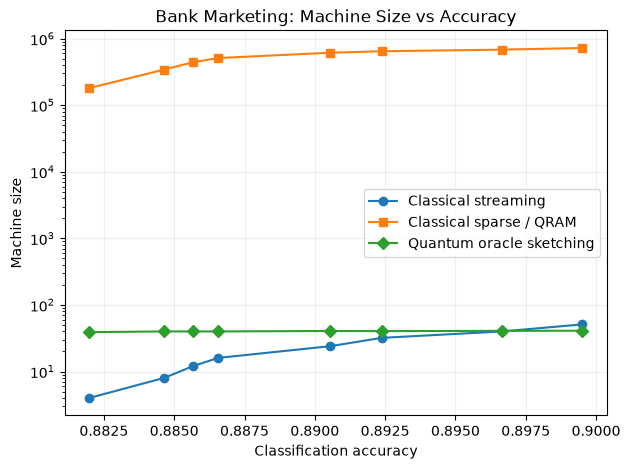

In [20]:
plt.figure(figsize=(7, 5))
plt.plot(summary['paper_accuracy_mean'], summary['streaming_size'], marker='o', label='Classical streaming')
plt.plot(summary['paper_accuracy_mean'], summary['sparse_size'], marker='s', label='Classical sparse / QRAM')
plt.plot(summary['paper_accuracy_mean'], summary['qos_size'], marker='D', label='Quantum oracle sketching')
plt.yscale('log')
plt.xlabel('Classification accuracy')
plt.ylabel('Machine size')
plt.title('Bank Marketing: Machine Size vs Accuracy')
plt.legend()
plt.grid(True, alpha=0.2)
plt.savefig(OUTPUT_DIR / 'bank_machine_size_vs_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()

In [21]:
results_df.to_csv(OUTPUT_DIR / 'bank_bucket_sweep_raw.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'bank_bucket_sweep_summary.csv', index=False)

### Balanced signed sparse JL

The imported JL implementation always returns CSR and uses validated
`sparsity=1`. Its permutation-then-sign RNG order and occupancy normalization
are unchanged. Higher sparsity is rejected: the reference has multi-round
collision repair that this Bank experiment has not validated.

Both methods use the same explicit dimensions, sketch seeds, and shuffled CV
splitter. Summaries report means and **sample standard deviations across
seed-level CV means**, not the reference's flattened-score SEM.

In [22]:
X_jl_16 = sparse_jl_features(
    X_full,
    n_buckets=16,
    seed=42,
    sparsity=1
)

print(X_jl_16.shape)
print(type(X_jl_16))

(45211, 16)
<class 'scipy.sparse._csr.csr_matrix'>


In [23]:
jl16_accuracy = cross_validation_scores(
    make_ridge_classifier(
        alpha=ALPHA,
        solver=SOLVER
    ),
    X_jl_16,
    y,
    cv=cv,
    scoring="accuracy"
)

jl16_balanced = cross_validation_scores(
    make_ridge_classifier(
        alpha=ALPHA,
        solver=SOLVER,
        class_weight="balanced"
    ),
    X_jl_16,
    y,
    cv=cv,
    scoring="balanced_accuracy"
)

print(
    "JL k=16 mean accuracy:",
    jl16_accuracy.mean()
)

print(
    "JL k=16 balanced accuracy:",
    jl16_balanced.mean()
)

JL k=16 mean accuracy: 0.8881687784160237
JL k=16 balanced accuracy: 0.773996117098497


In [24]:
started = perf_counter()
jl_results_df = run_sketch_sweep(
    X_full, y, sparse_jl_features,
    dimensions=bucket_sizes, seeds=seeds, cv=cv,
    sparsity_fn=max_row_sparsity, nnz_fn=matrix_nnz,
    qos_size_fn=qos_svm_machine_size,
)
sweep_seconds["sparse_jl"] = perf_counter() - started
print("Sparse JL runs:", len(jl_results_df), "seconds:", sweep_seconds["sparse_jl"])

Sparse JL runs: 40 seconds: 14.769440582953393


In [25]:
jl_summary = summarize_sweep(jl_results_df)
jl_summary

,k,paper_accuracy_mean,paper_accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,streaming_size,sparse_size,qos_size,max_sparsity
0,4,0.882993,0.000084,0.637501,0.035582,4.0,177248.2,39.0,4.0
1,8,0.884276,0.000983,0.709954,0.023131,8.0,323417.2,40.0,8.0
2,12,0.885324,0.001554,0.731291,0.024350,12.0,410229.4,40.0,12.0
3,16,0.886793,0.001823,0.760068,0.015377,16.0,486073.0,40.0,14.0
4,24,0.890699,0.002288,0.788665,0.020838,24.0,595936.4,40.6,15.6
5,32,0.893676,0.003404,0.804897,0.019152,32.0,632113.6,40.4,15.4
6,40,0.896419,0.002675,0.807913,0.013961,40.0,678769.4,40.8,15.8
7,51,0.899538,0.000000,0.825607,0.000000,51.0,723376.0,41.0,16.0


In [26]:
jl_results_df.to_csv(OUTPUT_DIR / 'bank_sparse_jl_sweep_raw.csv', index=False)
jl_summary.to_csv(OUTPUT_DIR / 'bank_sparse_jl_sweep_summary.csv', index=False)

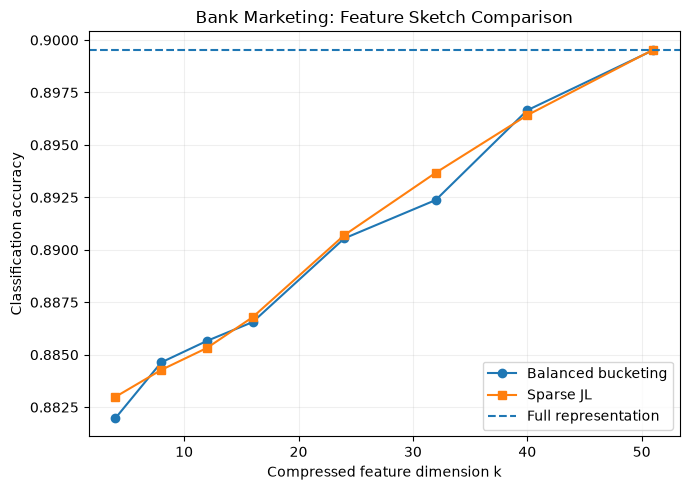

In [27]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(summary['k'], summary['paper_accuracy_mean'], marker='o', label='Balanced bucketing')
ax.plot(jl_summary['k'], jl_summary['paper_accuracy_mean'], marker='s', label='Sparse JL')
ax.axhline(paper_accuracy.mean(), linestyle='--', label='Full representation')
ax.set_xlabel('Compressed feature dimension k')
ax.set_ylabel('Classification accuracy')
ax.set_title('Bank Marketing: Feature Sketch Comparison')
ax.legend()
ax.grid(True, alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'bank_bucket_vs_sparse_jl.png', dpi=300, bbox_inches='tight')
plt.show()

In [28]:
comparison = (
    summary[
        [
            "k",
            "paper_accuracy_mean",
            "balanced_accuracy_mean",
            "streaming_size",
            "sparse_size",
            "qos_size"
        ]
    ]
    .merge(
        jl_summary[
            [
                "k",
                "paper_accuracy_mean",
                "balanced_accuracy_mean",
                "streaming_size",
                "sparse_size",
                "qos_size"
            ]
        ],
        on="k",
        suffixes=("_bucket", "_jl")
    )
)

comparison["paper_acc_delta_jl_minus_bucket"] = (
    comparison["paper_accuracy_mean_jl"]
    - comparison["paper_accuracy_mean_bucket"]
)

comparison["balanced_acc_delta_jl_minus_bucket"] = (
    comparison["balanced_accuracy_mean_jl"]
    - comparison["balanced_accuracy_mean_bucket"]
)

comparison

,k,paper_accuracy_mean_bucket,balanced_accuracy_mean_bucket,streaming_size_bucket,sparse_size_bucket,qos_size_bucket,paper_accuracy_mean_jl,balanced_accuracy_mean_jl,streaming_size_jl,sparse_size_jl,qos_size_jl,paper_acc_delta_jl_minus_bucket,balanced_acc_delta_jl_minus_bucket
0,4,0.881980,0.690836,4.0,180844.0,39.0,0.882993,0.637501,4.0,177248.2,39.0,0.001013,-0.053336
1,8,0.884634,0.735104,8.0,342373.2,40.0,0.884276,0.709954,8.0,323417.2,40.0,-0.000358,-0.025150
2,12,0.885661,0.755472,12.0,440903.8,40.0,0.885324,0.731291,12.0,410229.4,40.0,-0.000336,-0.024181
3,16,0.886559,0.776700,16.0,511290.2,40.0,0.886793,0.760068,16.0,486073.0,40.0,0.000234,-0.016632
4,24,0.890544,0.795980,24.0,614357.2,40.6,0.890699,0.788665,24.0,595936.4,40.6,0.000155,-0.007316
5,32,0.892376,0.804417,32.0,646264.0,40.4,0.893676,0.804897,32.0,632113.6,40.4,0.001301,0.000481
6,40,0.896653,0.811685,40.0,683387.2,40.8,0.896419,0.807913,40.0,678769.4,40.8,-0.000234,-0.003772
7,51,0.899516,0.825619,51.0,723376.0,41.0,0.899538,0.825607,51.0,723376.0,41.0,0.000022,-0.000013


In [29]:
comparison.to_csv(OUTPUT_DIR / 'bank_bucket_vs_jl_comparison.csv', index=False)

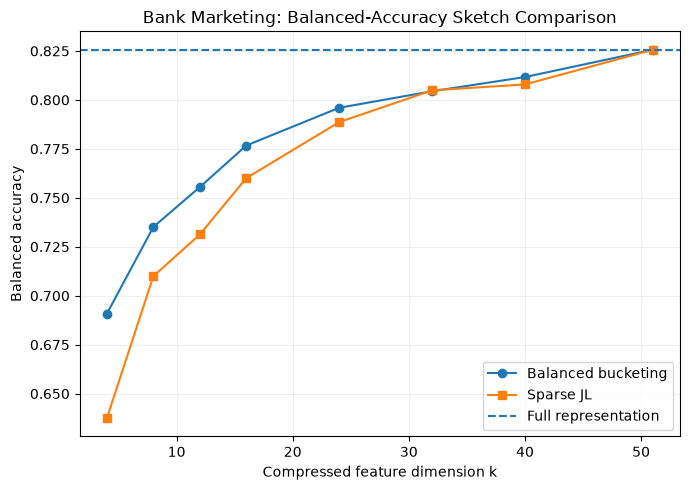

In [30]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(summary['k'], summary['balanced_accuracy_mean'], marker='o', label='Balanced bucketing')
ax.plot(jl_summary['k'], jl_summary['balanced_accuracy_mean'], marker='s', label='Sparse JL')
ax.axhline(balanced_accuracy.mean(), linestyle='--', label='Full representation')
ax.set_xlabel('Compressed feature dimension k')
ax.set_ylabel('Balanced accuracy')
ax.set_title('Bank Marketing: Balanced-Accuracy Sketch Comparison')
ax.legend()
ax.grid(True, alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'bank_bucket_vs_sparse_jl_balanced.png', dpi=300, bbox_inches='tight')
plt.show()

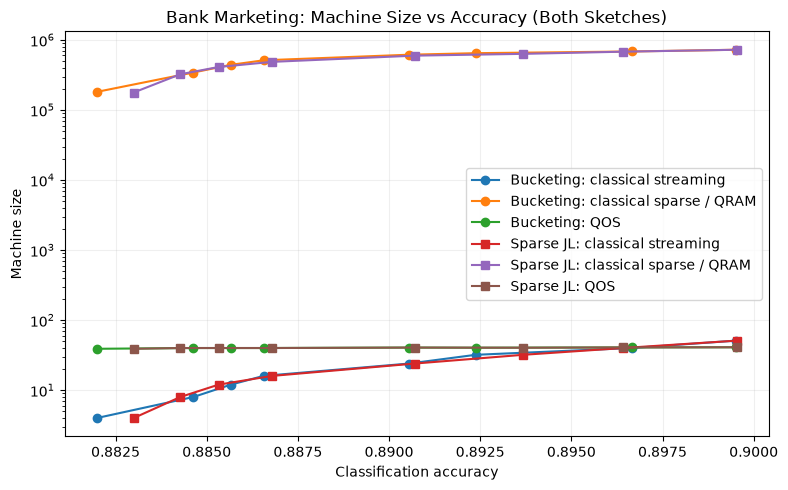

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(summary['paper_accuracy_mean'], summary['streaming_size'], marker='o', label='Bucketing: classical streaming')
ax.plot(summary['paper_accuracy_mean'], summary['sparse_size'], marker='o', label='Bucketing: classical sparse / QRAM')
ax.plot(summary['paper_accuracy_mean'], summary['qos_size'], marker='o', label='Bucketing: QOS')
ax.plot(jl_summary['paper_accuracy_mean'], jl_summary['streaming_size'], marker='s', label='Sparse JL: classical streaming')
ax.plot(jl_summary['paper_accuracy_mean'], jl_summary['sparse_size'], marker='s', label='Sparse JL: classical sparse / QRAM')
ax.plot(jl_summary['paper_accuracy_mean'], jl_summary['qos_size'], marker='s', label='Sparse JL: QOS')
ax.set_yscale('log')
ax.set_xlabel('Classification accuracy')
ax.set_ylabel('Machine size')
ax.set_title('Bank Marketing: Machine Size vs Accuracy (Both Sketches)')
ax.legend()
ax.grid(True, alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'bank_machine_size_vs_accuracy_both_sketches.png', dpi=300, bbox_inches='tight')
plt.show()

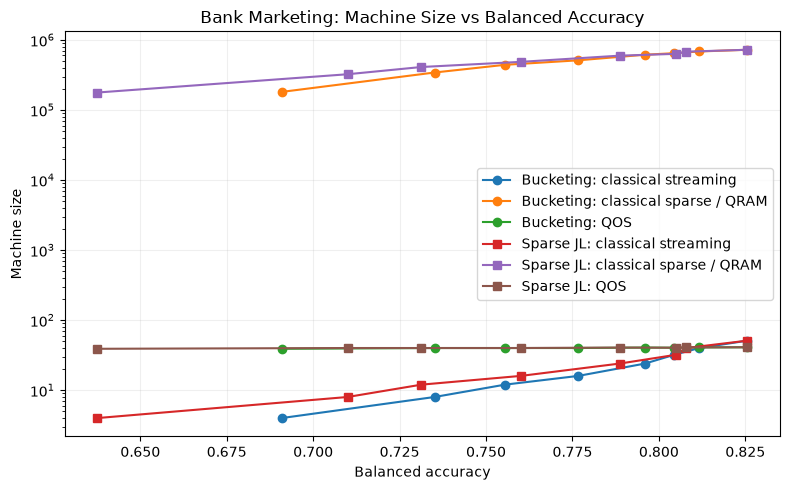

In [32]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(summary['balanced_accuracy_mean'], summary['streaming_size'], marker='o', label='Bucketing: classical streaming')
ax.plot(summary['balanced_accuracy_mean'], summary['sparse_size'], marker='o', label='Bucketing: classical sparse / QRAM')
ax.plot(summary['balanced_accuracy_mean'], summary['qos_size'], marker='o', label='Bucketing: QOS')
ax.plot(jl_summary['balanced_accuracy_mean'], jl_summary['streaming_size'], marker='s', label='Sparse JL: classical streaming')
ax.plot(jl_summary['balanced_accuracy_mean'], jl_summary['sparse_size'], marker='s', label='Sparse JL: classical sparse / QRAM')
ax.plot(jl_summary['balanced_accuracy_mean'], jl_summary['qos_size'], marker='s', label='Sparse JL: QOS')
ax.set_yscale('log')
ax.set_xlabel('Balanced accuracy')
ax.set_ylabel('Machine size')
ax.set_title('Bank Marketing: Machine Size vs Balanced Accuracy')
ax.legend()
ax.grid(True, alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'bank_machine_size_vs_balanced_accuracy_both_sketches.png', dpi=300, bbox_inches='tight')
plt.show()

### Interpretation and limits

Both balanced bucketing and sparse JL preserve much of the ordinary accuracy
under compression. Balanced bucketing generally preserves balanced accuracy
better at aggressive compression; ordinary accuracy alone is insufficient for
this imbalanced dataset. Neither result demonstrates practical quantum advantage.

The row-only QOS estimate remains roughly 39–41 accounting units. Explicit sparse
storage counts many more nonzero values, but the classical streaming dimension
is already small because the full encoding has only 51 features. Bank Marketing
is therefore a **pipeline-validation dataset**, not strong evidence of a useful
QOS scaling advantage.

At full dimension, dense bucketing and CSR JL preserve the same feature values
but can have slightly different scores because `solver="auto"` selects different
solvers. The historical leakage, resource convention, and aggregation described
above remain unchanged. No new dataset or methodology is introduced here.

In [33]:
# Compare the newly exported CSVs with the immutable original artifacts.
# Keep the established regression tolerance; never widen it to hide drift.
ATOL = 1e-8
csv_names = [
    "bank_bucket_sweep_raw.csv", "bank_bucket_sweep_summary.csv",
    "bank_sparse_jl_sweep_raw.csv", "bank_sparse_jl_sweep_summary.csv",
    "bank_bucket_vs_jl_comparison.csv",
]
csv_comparisons = []
for filename in csv_names:
    actual = pd.read_csv(OUTPUT_DIR / filename)
    expected = pd.read_csv(ROOT / "results" / filename)
    pd.testing.assert_frame_equal(actual, expected, check_dtype=False, rtol=0, atol=ATOL)
    # Discrete identifiers and resource counts must agree exactly, not just within tolerance.
    exact_columns = [c for c in actual if c in ("k", "seed", "streaming_size", "sparse_size", "qos_size", "max_sparsity")]
    np.testing.assert_array_equal(actual[exact_columns].to_numpy(), expected[exact_columns].to_numpy())
    csv_comparisons.append({"file": filename, "rows": len(actual),
                            "max_absolute_difference": float(np.abs(actual.to_numpy() - expected.to_numpy()).max())})
assert len(results_df) == len(jl_results_df) == 40
assert X_encoded.shape == (45211, 51)
assert (N, D, s, nnz, qos_machine_size) == (45211, 51, 16, 723376, 41)

baseline_values = {
    "paper_accuracy": float(paper_accuracy.mean()),
    "paper_balanced_accuracy": float(paper_balanced_accuracy.mean()),
    "balanced_accuracy": float(balanced_accuracy.mean()),
    "jl_endpoint_accuracy": float(jl_results_df.loc[jl_results_df.k == D, "paper_accuracy"].iloc[0]),
    "jl_endpoint_balanced_accuracy": float(jl_results_df.loc[jl_results_df.k == D, "balanced_accuracy"].iloc[0]),
}
expected_baselines = {
    "paper_accuracy": 0.8995155858234207,
    "paper_balanced_accuracy": 0.6300640934600773,
    "balanced_accuracy": 0.8256193229214974,
    "jl_endpoint_accuracy": 0.899537704823642,
    "jl_endpoint_balanced_accuracy": 0.8256067994399695,
}
for name, expected in expected_baselines.items():
    np.testing.assert_allclose(baseline_values[name], expected, rtol=0, atol=ATOL)

validation_report = {
    "status": "passed", "atol": ATOL, "rtol": 0,
    "shape": [N, D], "max_row_sparsity": s, "nnz": nnz,
    "qos_size": qos_machine_size, "baseline_values": baseline_values,
    "csv_comparisons": csv_comparisons, "sweep_seconds": sweep_seconds,
    "dense_encoded_array_bytes": X_full.nbytes,
}
(OUTPUT_DIR / "validation_report.json").write_text(json.dumps(validation_report, indent=2) + "\n")
print("All 80 sketch runs, both summaries, comparison table, and baselines match within tolerance.")
print("Dense encoded array payload (MiB):", X_full.nbytes / 2**20)
print("Validation report:", OUTPUT_DIR / "validation_report.json")
pd.DataFrame(csv_comparisons)

All 80 sketch runs, both summaries, comparison table, and baselines match within tolerance.
Dense encoded array payload (MiB): 17.59156036376953
Validation report: /Users/Surface/code/qos-rbc-experiments/validation/bank_marketing/run-29qfoy4_/validation_report.json


,file,rows,max_absolute_difference
0,bank_bucket_sweep_raw.csv,40,0.0
1,bank_bucket_sweep_summary.csv,8,0.0
2,bank_sparse_jl_sweep_raw.csv,40,0.0
3,bank_sparse_jl_sweep_summary.csv,8,0.0
4,bank_bucket_vs_jl_comparison.csv,8,0.0
